# 🦟 Módulo 1 – CNN para Clasificación de Mosquitos
**Proyecto VectorIA** | Redes Neuronales Convolucionales

## Orden de ejecución:
1. Montar Google Drive y extraer el dataset
2. Instalar dependencias
3. Copiar el código fuente (`../src`)
4. Cargar datos y construir el modelo
5. Entrenar con callbacks y class_weights
6. Evaluar en test (F1-Score macro, Matriz de Confusión)
7. Descargar el modelo entrenado

---
## 🔌 Celda 1 – Verificar GPU disponible en Colab
> Ve a **Entorno de ejecución → Cambiar tipo de entorno → GPU T4**

In [ ]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ GPU detectada: {gpus[0].name}")
else:
    print("⚠️  No se detectó GPU. Ve a Entorno de ejecución → Cambiar tipo de entorno → GPU T4")

✅ GPU detectada: /physical_device:GPU:0


---
## 📂 Celda 2 – Montar Google Drive
> **Antes de correr esta celda:**
> 1. Comprime tu carpeta `data/processed/` en un archivo `processed.zip`
> 2. Sube `processed.zip` a tu Google Drive (raíz o carpeta de tu preferencia)
> 3. También sube la carpeta `../src` completa a Drive (o solo `src/train/cnn.py`)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
print("✅ Google Drive montado correctamente")

Mounted at /content/drive
✅ Google Drive montado correctamente


---
## 📦 Celda 3 – Extraer el dataset en el entorno de Colab
> Ajusta `RUTA_ZIP` a donde subiste tu archivo en Drive

In [ ]:
import zipfile
import os

# ⚠️ AJUSTA ESTA RUTA si subiste el zip a una subcarpeta de Drive
RUTA_ZIP = "/content/drive/MyDrive/processed.zip"
RUTA_DESTINO = "/content/data"

os.makedirs(RUTA_DESTINO, exist_ok=True)

with zipfile.ZipFile(RUTA_ZIP, 'r') as zip_ref:
    zip_ref.extractall(RUTA_DESTINO)

print("✅ Dataset extraído en:", RUTA_DESTINO)

# Verificar estructura de carpetas
for split in ['train', 'val', 'test']:
    split_path = os.path.join(RUTA_DESTINO, 'processed', split)
    if os.path.exists(split_path):
        clases = os.listdir(split_path)
        total = sum(len(os.listdir(os.path.join(split_path, c))) for c in clases)
        print(f"  📁 {split}: {total} imágenes en {len(clases)} clases")
    else:
        print(f"  ⚠️  No se encontró la carpeta {split_path}")

✅ Dataset extraído en: /content/data
  📁 train: 2828 imágenes en 3 clases
  📁 val: 353 imágenes en 3 clases
  📁 test: 354 imágenes en 3 clases


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## 🛠️ Celda 4 – Copiar el código fuente a Colab

In [ ]:
import shutil
import os

# ⚠️ AJUSTA esta ruta a donde subiste tu carpeta src/ en Drive
# Si subiste la carpeta completa como 'src', cambia 'train' por 'src'
RUTA_SRC_EN_DRIVE = "/content/drive/MyDrive/src"
RUTA_SRC_EN_COLAB = "/content/src"

# Validación previa para guiarte en caso de que persista el error
if not os.path.exists(RUTA_SRC_EN_DRIVE):
    # Intenta buscar una ruta alternativa común
    alternativa = "/content/drive/MyDrive/train"
    if os.path.exists(alternativa):
        RUTA_SRC_EN_DRIVE = alternativa
    else:
        raise FileNotFoundError(f"❌ No se encontró la carpeta en '{RUTA_SRC_EN_DRIVE}' ni en '{alternativa}'. Asegúrate de haberla subido a Google Drive y que el nombre sea correcto.")

if os.path.exists(RUTA_SRC_EN_COLAB):
    shutil.rmtree(RUTA_SRC_EN_COLAB)

shutil.copytree(RUTA_SRC_EN_DRIVE, RUTA_SRC_EN_COLAB)

# Crear carpeta para guardar el modelo entrenado
os.makedirs("/content/models", exist_ok=True)

print(f"✅ Código fuente copiado con éxito desde {RUTA_SRC_EN_DRIVE} a {RUTA_SRC_EN_COLAB}")
print("✅ Carpeta /content/models lista para guardar el modelo")

✅ Código fuente copiado con éxito desde /content/drive/MyDrive/train a /content/src
✅ Carpeta /content/models lista para guardar el modelo


---
## ⚙️ Celda 5 – Configurar rutas y parámetros del experimento

In [ ]:
import sys
sys.path.insert(0, '/content')  # Para que Python encuentre src/

from src.cnn import EntrenarCNN

# ── Rutas ──────────────────────────────────────────────
DATA_DIR    = "/content/data/processed"
MODEL_PATH  = "/content/models/cnn_propia.keras"

# ── Hiperparámetros ────────────────────────────────────
IMG_SIZE    = (224, 224)   # Tamaño de imagen (coincide con MobileNetV2)
BATCH_SIZE  = 64           # Reducir a 16 si Colab da error de memoria
EPOCHS      = 80          # EarlyStopping frenará antes si no mejora

print(f"📌 Configuración del experimento:")
print(f"   Tamaño imagen : {IMG_SIZE}")
print(f"   Batch size    : {BATCH_SIZE}")
print(f"   Épocas máx    : {EPOCHS}")
print(f"   Ruta datos    : {DATA_DIR}")
print(f"   Guardar modelo: {MODEL_PATH}")

📌 Configuración del experimento:
   Tamaño imagen : (224, 224)
   Batch size    : 64
   Épocas máx    : 80
   Ruta datos    : /content/data/processed
   Guardar modelo: /content/models/cnn_propia.keras


---
## 📥 Celda 6 – Cargar los datos desde `data/processed/`

In [ ]:
cnn = EntrenarCNN(
    data_dir   = DATA_DIR,
    img_size   = IMG_SIZE,
    batch_size = BATCH_SIZE
)

cnn.cargar_datos()

print(f"\n🏷️  Clases detectadas : {cnn.class_names}")
print(f"   0 → {cnn.class_names[0]}")
print(f"   1 → {cnn.class_names[1]}")
print(f"   2 → {cnn.class_names[2]}")

Found 2828 files belonging to 3 classes.
Found 353 files belonging to 3 classes.
Found 354 files belonging to 3 classes.
✓ Datos cargados exitosamente. Clases: ['aegypti', 'albopictus', 'culex']

🏷️  Clases detectadas : ['aegypti', 'albopictus', 'culex']
   0 → aegypti
   1 → albopictus
   2 → culex


---
## ⚖️ Celda 7 – Calcular pesos de clase (Compensar desbalance de *Culex*)

In [ ]:
pesos = cnn.calcular_pesos_clases()

print("\n📊 Interpretación de los pesos:")
for idx, clase in enumerate(cnn.class_names):
    print(f"   Clase {idx} ({clase}): peso = {pesos[idx]:.4f}")

print("\n💡 La clase con mayor peso es la que tiene menos imágenes (Culex).")
print("   La red prestará más atención a sus errores durante el entrenamiento.")

✓ Pesos calculados para balancear el entrenamiento:
{0: 0.7868670005564831, 1: 0.91343669250646, 2: 1.576365663322185}

📊 Interpretación de los pesos:
   Clase 0 (aegypti): peso = 0.7869
   Clase 1 (albopictus): peso = 0.9134
   Clase 2 (culex): peso = 1.5764

💡 La clase con mayor peso es la que tiene menos imágenes (Culex).
   La red prestará más atención a sus errores durante el entrenamiento.


---
## 🧠 Celda 8 – Construir la arquitectura CNN

In [ ]:
cnn.construir_modelo()

# El summary() ya se imprime dentro del método.
# Fíjate en:
#   - Total params: cuántos parámetros tiene la red
#   - Trainable params: los que se van a ajustar durante el entrenamiento

Model: "CNN_V6_Con_Atencion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip         │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation     │ (None, 224, 224,  │          0 │ random_flip[0][0] │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom         │ (None, 224, 224,  │          0 │ random_rotation[… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_translation  │ (None, 224, 224,  │          0 │ random_zoom[0][0] │
│ (RandomTranslation) │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ random_translati… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │      1,792 │ rescaling[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 64)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 4)   │        256 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 64)  │        256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ multiply[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        512 │ conv2d_2[0][0]  

 Total params: 1,227,331 (4.68 MB)

 Trainable params: 1,225,027 (4.67 MB)

 Non-trainable params: 2,304 (9.00 KB)

<Functional name=CNN_V6_Con_Atencion, built=True>

---
## 🚀 Celda 9 – Compilar y Entrenar
> ⏱️ Con GPU T4 de Colab, 50 épocas tardan aproximadamente 5-15 minutos.
>
> `EarlyStopping` frenará automáticamente si no mejora en 5 épocas consecutivas.

In [ ]:
# Actualizamos la ruta del ModelCheckpoint para que guarde en Colab
import tensorflow.keras as keras

historia = cnn.compilar_y_entrenar(
    epochs       = EPOCHS,
    #class_weights = pesos
)

Iniciando entrenamiento por máximo 80 épocas:
Epoch 1/80
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5551 - f1_macro: 0.5481 - loss: 1.1744 - precision: 0.5862 - recall: 0.5083
Epoch 1: val_f1_macro improved from None to 0.19788, saving model to models/cnn_propia_best.keras

Epoch 1: finished saving model to models/cnn_propia_best.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.6079 - f1_macro: 0.6000 - loss: 1.0638 - precision: 0.6418 - recall: 0.5587 - val_accuracy: 0.4221 - val_f1_macro: 0.1979 - val_loss: 1.0826 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/80
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6321 - f1_macro: 0.6302 - loss: 0.9609 - precision: 0.6855 - recall: 0.5701
Epoch 2: val_f1_macro did not improve from 0.19788
45/45 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.6326 - f1_macro: 0.6301 - loss: 0.9559 - precision: 0.6820 - recall: 0.5711 - val_accuracy: 0.4221 - val_f1_macro: 0.1979 - val_loss: 

---
## 📈 Celda 10 – Curvas de Aprendizaje (Diagnóstico de Overfitting)

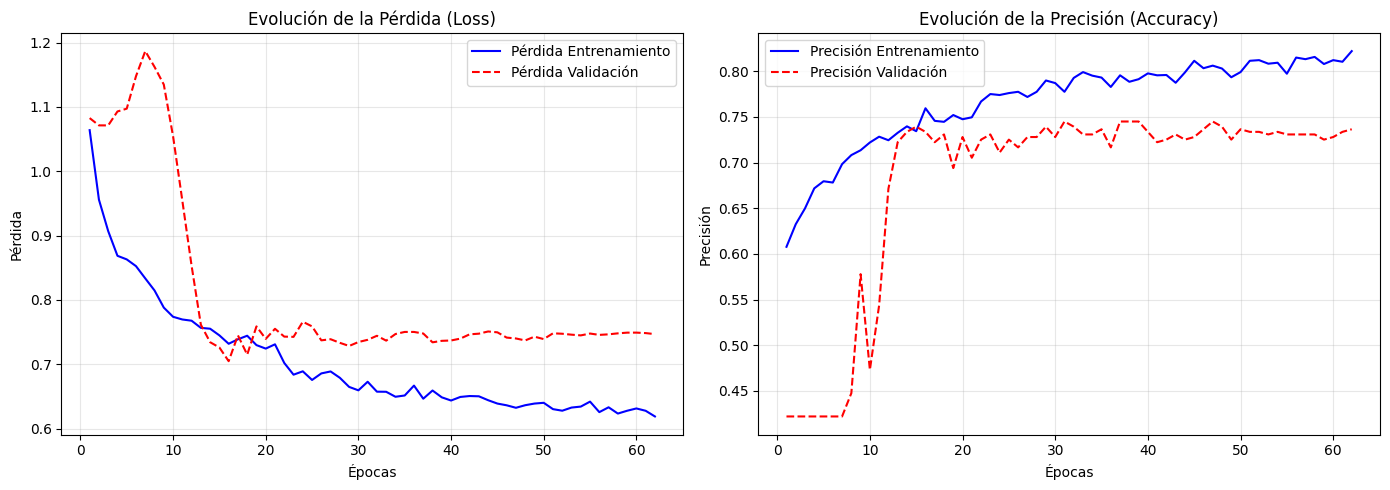

In [ ]:
from src.cnn import DiagnosticoEvaluacion

# Instanciamos la clase de evaluación con el modelo entrenado y sus datos
evaluador = DiagnosticoEvaluacion(
    modelo=cnn.modelo,
    historia=historia,
    test_ds=cnn.test_ds,
    class_names=cnn.class_names
)

# Graficamos las métricas usando el método de tu clase
evaluador.graficar_metricas()

---
## 🎯 Celda 11 – Evaluación Final en el Conjunto de Prueba (Test)
> **Métrica oficial de la rúbrica:** F1-Score Macro ≥ 85%

Evaluando el modelo en el conjunto de prueba (Test)...
6/6 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step

REPORTE DE CLASIFICACIÓN (MÉTRICAS OFICIALES)
              precision    recall  f1-score   support

     aegypti     0.7098    0.9133    0.7988       150
  albopictus     0.8515    0.6667    0.7478       129
       culex     1.0000    0.8000    0.8889        75

    accuracy                         0.7994       354
   macro avg     0.8538    0.7933    0.8118       354
weighted avg     0.8229    0.7994    0.7993       354



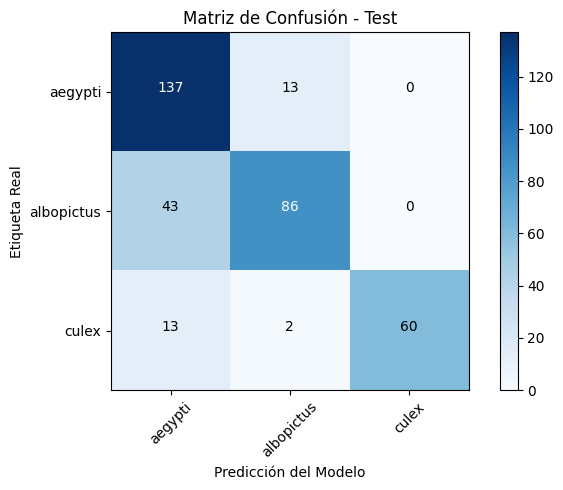

In [ ]:
# Evaluamos el conjunto de prueba usando el método oficial de DiagnosticoEvaluacion
evaluador.evaluar_test()

---
## 💾 Celda 12 – Guardar el modelo entrenado en Google Drive

In [ ]:
# Guardamos el modelo en Drive para no perderlo cuando se reinicie Colab
RUTA_MODELO_DRIVE = "/content/drive/MyDrive/cnn_propia.keras"
cnn.modelo.save(RUTA_MODELO_DRIVE)
print(f"✅ Modelo guardado en Google Drive: {RUTA_MODELO_DRIVE}")
print("   Descárgalo y cópialo a tu carpeta local models/cnn_propia.keras")

✅ Modelo guardado en Google Drive: /content/drive/MyDrive/cnn_propia.keras
   Descárgalo y cópialo a tu carpeta local models/cnn_propia.keras


---
# 🚀 Módulo 1.2 – MobileNetV2 (Transfer Learning & Fine-Tuning)
**Comparación exigida por la rúbrica para superar el umbral F1-Score Macro ≥ 85%**

MobileNetV2 fue pre-entrenado con millones de imágenes en ImageNet.
Lo entrenamos en dos etapas:
1. **Fase 1 (Extracción de Características):** Base congelada, entrenando solo la cabeza.
2. **Fase 2 (Fine-Tuning):** Descongelando las últimas 30 capas con un Learning Rate diminuto (1e-5).

---
## 📥 Celda 13 – Cargar datos a 224x224 y construir MobileNetV2

In [ ]:
from src.cnn_mobilenetv2 import EntrenarMobileNetV2
from src.cnn import DiagnosticoEvaluacion

# 1. Instanciamos el entrenador a 224x224 (tamaño nativo de MobileNetV2)
mb = EntrenarMobileNetV2(
    data_dir="/content/data/processed",
    img_size=(224, 224),
    batch_size=32
)

# 2. Cargar datos con preprocess_input (-1 a 1)
mb.cargar_datos()

# 3. Calcular pesos para el desbalance de Culex
pesos_mb = mb.calcular_pesos_clases()

# 4. Descargar base ImageNet y ensamblar la cabeza clasificadora
mb.construir_modelo()

Found 2828 files belonging to 3 classes.
Found 353 files belonging to 3 classes.
Found 354 files belonging to 3 classes.
✓ Datos cargados exitosamente. Clases: ['aegypti', 'albopictus', 'culex']
✓ Pesos calculados para balancear el entrenamiento:
{0: 0.7868670005564831, 1: 0.91343669250646, 2: 1.576365663322185}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Mosquitos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,620,227 (10.00 MB)

 Trainable params: 361,731 (1.38 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

<Functional name=MobileNetV2_Mosquitos, built=True>

---
## 🔒 Celda 14 – Fase 1: Entrenar con la Base Congelada (15 épocas máx)
> Solo aprende la cabeza clasificadora recién agregada con `learning_rate=1e-3`.
> Debería alcanzar ~82-85% rápidamente.

In [ ]:
historia_f1 = mb.entrenar_fase1(epochs=15, class_weights=pesos_mb)


FASE 1: EXTRACCIÓN DE CARACTERÍSTICAS (Base Congelada)
Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 588ms/step - accuracy: 0.6138 - f1_macro: 0.6211 - loss: 0.8913 - precision: 0.6344 - recall: 0.5724
Epoch 1: val_f1_macro improved from None to 0.76858, saving model to models/mobilenetv2_fase1.keras

Epoch 1: finished saving model to models/mobilenetv2_fase1.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 78s 685ms/step - accuracy: 0.6789 - f1_macro: 0.6930 - loss: 0.7505 - precision: 0.6992 - recall: 0.6460 - val_accuracy: 0.7649 - val_f1_macro: 0.7686 - val_loss: 0.6155 - val_precision: 0.8068 - val_recall: 0.6742 - learning_rate: 0.0010
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 570ms/step - accuracy: 0.7451 - f1_macro: 0.7620 - loss: 0.5978 - precision: 0.7650 - recall: 0.7184
Epoch 2: val_f1_macro improved from 0.76858 to 0.79906, saving model to models/mobilenetv2_fase1.keras

Epoch 2: finished saving model to models/mobilenetv2_fase1.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 58s 643ms/step - accuracy: 0.748

---
## 🔓 Celda 15 – Fase 2: Fine-Tuning de las últimas 30 capas (15 épocas adicionales)
> Descongela las capas más profundas de MobileNetV2 para que reconozcan los detalles del tórax.
> Usa `learning_rate=1e-5` (100 veces más pequeño) para no destruir los pesos pre-entrenados.

In [ ]:
historia_f2 = mb.entrenar_fine_tuning(
    epochs_adicionales=15,
    capas_a_descongelar=40,
    class_weights=pesos_mb
)


FASE 2: FINE-TUNING (Descongelando últimas 40 capas)
Capas entrenables en base_model: 26 (Excluyendo BatchNormalization)
Epoch 16/30
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.7834 - f1_macro: 0.8026 - loss: 0.5240 - precision: 0.7975 - recall: 0.7605
Epoch 16: val_f1_macro improved from None to 0.74785, saving model to models/mobilenetv2_final.keras

Epoch 16: finished saving model to models/mobilenetv2_final.keras
89/89 ━━━━━━━━━━━━━━━━━━━━ 70s 686ms/step - accuracy: 0.7762 - f1_macro: 0.7962 - loss: 0.5296 - precision: 0.7904 - recall: 0.7532 - val_accuracy: 0.7252 - val_f1_macro: 0.7479 - val_loss: 0.6579 - val_precision: 0.7368 - val_recall: 0.7139 - learning_rate: 1.0000e-04
Epoch 17/30
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 552ms/step - accuracy: 0.8039 - f1_macro: 0.8203 - loss: 0.5191 - precision: 0.8186 - recall: 0.7773
Epoch 17: val_f1_macro did not improve from 0.74785
89/89 ━━━━━━━━━━━━━━━━━━━━ 59s 669ms/step - accuracy: 0.8041 - f1_macro: 0.8211 - loss: 0.5139 - preci

---
## 📊 Celda 16 – Evaluación y Diagnóstico con tu clase `DiagnosticoEvaluacion`
> Gráficos de curvas de aprendizaje, F1-Score Macro y Matriz de Confusión sobre el conjunto Test.

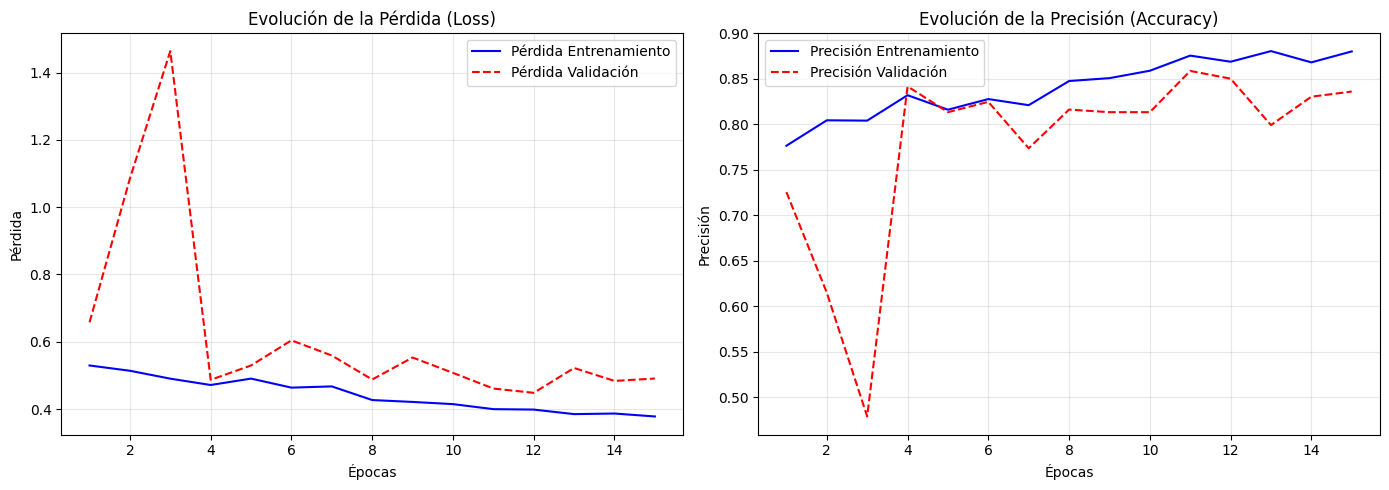

Evaluando el modelo en el conjunto de prueba (Test)...
12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 782ms/step

REPORTE DE CLASIFICACIÓN (MÉTRICAS OFICIALES)
              precision    recall  f1-score   support

     aegypti     0.7976    0.8933    0.8428       150
  albopictus     0.8559    0.7364    0.7917       129
       culex     1.0000    1.0000    1.0000        75

    accuracy                         0.8588       354
   macro avg     0.8845    0.8766    0.8781       354
weighted avg     0.8617    0.8588    0.8575       354



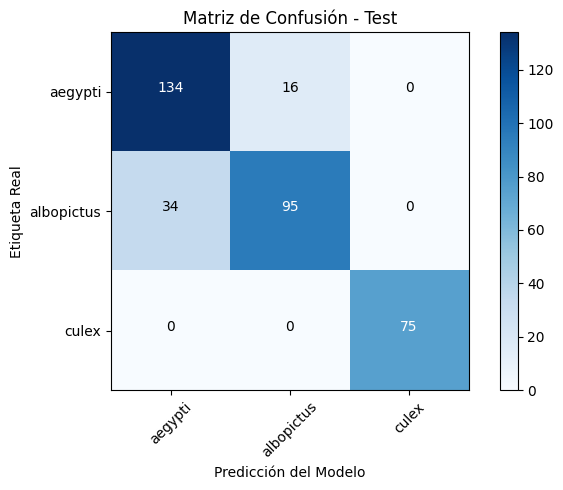

In [ ]:
evaluador_mb = DiagnosticoEvaluacion(
    modelo=mb.modelo,
    historia=historia_f2,
    test_ds=mb.test_ds,
    class_names=mb.class_names
)

# Curvas de pérdida y precisión en Fine-Tuning
evaluador_mb.graficar_metricas()

# Reporte oficial de métricas (F1-Score macro >= 85%) y Matriz de Confusión
evaluador_mb.evaluar_test()

---
## 💾 Celda 17 – Guardar el modelo MobileNetV2 final en Google Drive

In [ ]:
RUTA_MB_DRIVE = "/content/drive/MyDrive/mobilenetv2_final.keras"
mb.modelo.save(RUTA_MB_DRIVE)
print(f"✅ Modelo MobileNetV2 guardado en Google Drive: {RUTA_MB_DRIVE}")
print("   Descárgalo y cópialo a tu carpeta local models/mobilenetv2_final.keras")

✅ Modelo MobileNetV2 guardado en Google Drive: /content/drive/MyDrive/mobilenetv2_final.keras
   Descárgalo y cópialo a tu carpeta local models/mobilenetv2_final.keras
